
# Machine Learning Methodologies for Detecting Identity Theft in Buy-Now-Pay-Later Fintech Systems

**Postgraduate Diploma in Data Analytics — Research Project**

## Project Overview

This notebook documents the experimental evaluation of Logistic Regression, Random Forest and Support Vector Machine models for financial transaction fraud detection and identity theft. It includes dataset preprocessing, exploratory data analysis, SMOTE, hyperparameter optimisation and model evaluation.

The experiments use an anonymised credit card fraud dataset. The results provide insight into fraud detection methodologies but do not directly validate identity theft detection within BNPL systems.

## Python Libraries and Dependencies

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.svm import SVC

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from imblearn.pipeline import Pipeline


from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.base import clone

## 1. Dataset Loading and Data Cleaning


The Credit Card Fraud dataset was obtained from Kaggle. This section examines the dataset structure, missing values and duplicate records. After removing 1,081 duplicate observations, 283,726 transactions remained for analysis.

**Related report sections:** 3.5, 3.7 and 4.2.


### 1.1 - Load and Inspect Dataset

In [2]:
# Load the dataset
df = pd.read_csv("creditcard.csv")

# Display the first five rows
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,'0'
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,'0'
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,'0'
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,'0'
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,'0'


In [3]:
# Check the dimensions of the dataset
print("Dataset shape:", df.shape)

Dataset shape: (284807, 31)


In [4]:
# Check column names
print(df.columns)

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')


In [5]:
# Check data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

### 1.2 - Check Data Quality

In [6]:
# Check for missing values
print("Total missing values:", df.isnull().sum().sum())

# Check for duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check target variable
print(df["Class"].value_counts())


Total missing values: 0
Duplicate rows: 1081
Class
'0'    284315
'1'       492
Name: count, dtype: int64


### 1.3 - Fix Target Variable

In [7]:
df["Class"] = (
    df["Class"]
    .astype(str)
    .str.strip()
    .str.strip("'\"")
    .astype(int)
)

print(df["Class"].value_counts())
print(df["Class"].dtype)

Class
0    284315
1       492
Name: count, dtype: int64
int64


### 1.4 - Removing Duplicates

In [8]:
# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print(df["Class"].value_counts())

Dataset shape after removing duplicates: (283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


## 2. Exploratory Data Analysis

### 2.1 - Class Distribution

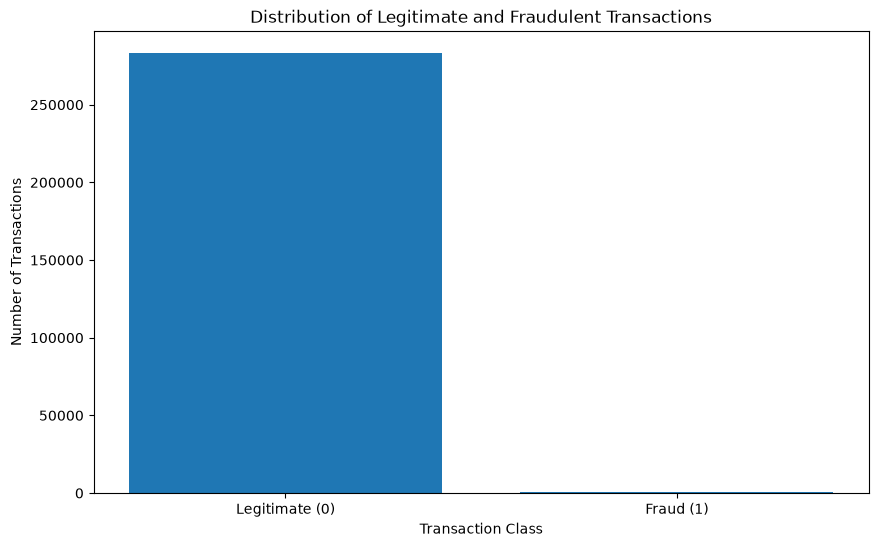

In [9]:
class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(10, 6))
plt.bar(["Legitimate (0)", "Fraud (1)"], class_counts.values)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.show()

### 2.2 - Analyze Transaction Amounts

In [10]:
amount_stats = df.groupby("Class")["Amount"].agg(["count", "mean", "median", "std", "min", "max"])

amount_stats

,count,mean,median,std,min,max
Class,,,,,,
0,283253,88.413575,22.00,250.379023,0.0,25691.16
1,473,123.871860,9.82,260.211041,0.0,2125.87


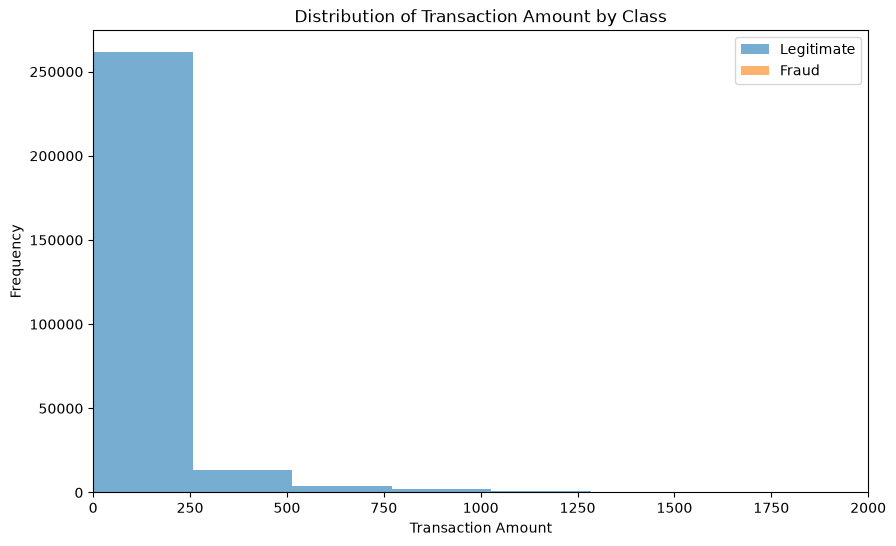

In [11]:
legitimate = df[df["Class"] == 0]
fraud = df[df["Class"] == 1]

plt.figure(figsize=(10, 6))

plt.hist(legitimate["Amount"], bins=100, alpha=0.6, label="Legitimate")

plt.hist(fraud["Amount"],bins=100,alpha=0.6,label="Fraud")

plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.title("Distribution of Transaction Amount by Class")
plt.legend()

plt.xlim(0, 2000)

plt.show()

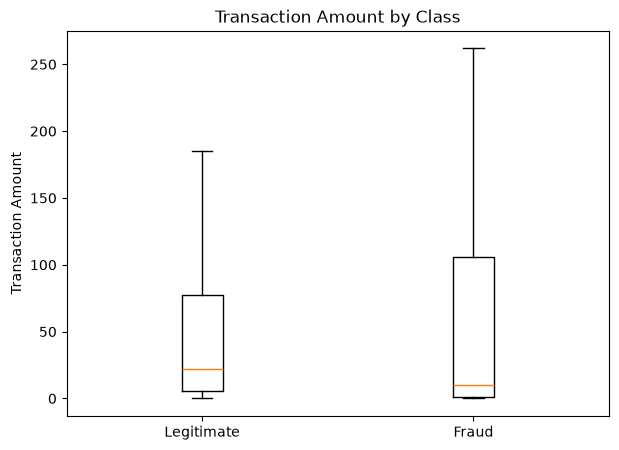

In [12]:
plt.figure(figsize=(7, 5))

plt.boxplot([legitimate["Amount"],fraud["Amount"]],tick_labels=["Legitimate", "Fraud"],showfliers=False)

plt.title("Transaction Amount by Class")
plt.ylabel("Transaction Amount")

plt.show()

### 2.3 - Analyze Transaction Times

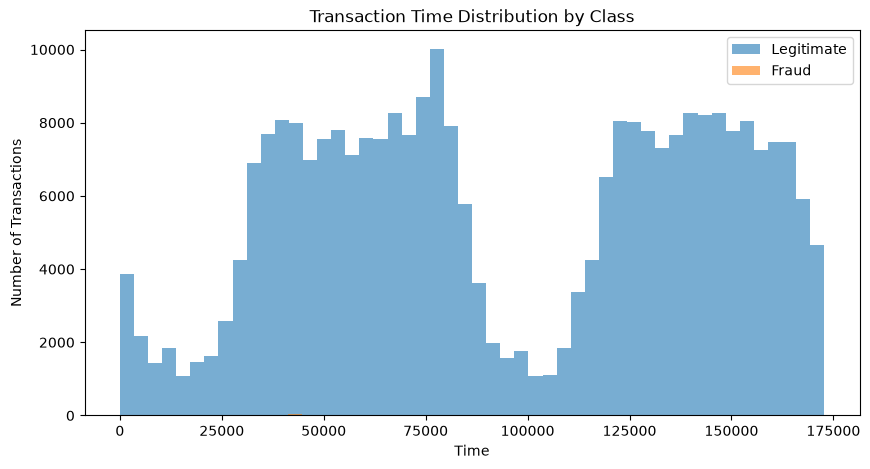

In [13]:
plt.figure(figsize=(10, 5))

plt.hist(legitimate["Time"],bins=50,alpha=0.6,label="Legitimate")

plt.hist(fraud["Time"],bins=50,alpha=0.6,label="Fraud")

plt.xlabel("Time")
plt.ylabel("Number of Transactions")
plt.title("Transaction Time Distribution by Class")
plt.legend()

plt.show()

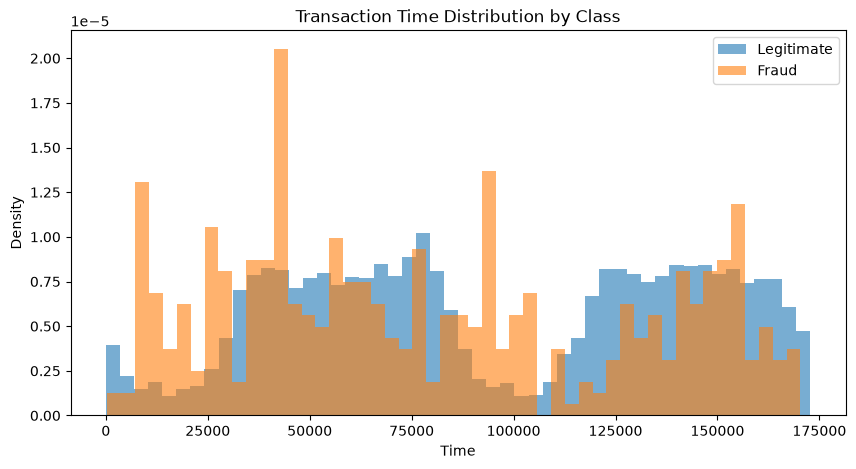

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(legitimate["Time"],bins=50,density=True,alpha=0.6,label="Legitimate")

plt.hist(fraud["Time"],bins=50,density=True,alpha=0.6,label="Fraud")

plt.xlabel("Time")
plt.ylabel("Density")
plt.title("Transaction Time Distribution by Class")
plt.legend()

plt.show()

### 2.4 - Correlation with Target Variable

In [15]:
correlations = (df.corr(numeric_only=True)["Class"].drop("Class").sort_values())

correlations

V17      -0.313498
V14      -0.293375
V12      -0.250711
V10      -0.206971
V16      -0.187186
V3       -0.182322
V7       -0.172347
V18      -0.105340
V1       -0.094486
V9       -0.094021
V5       -0.087812
V6       -0.043915
Time     -0.012359
V24      -0.007210
V23      -0.006333
V13      -0.003897
V15      -0.003300
V25       0.003202
V26       0.004265
V22       0.004887
Amount    0.005777
V28       0.009682
V20       0.021486
V27       0.021892
V21       0.026357
V8        0.033068
V19       0.033631
V2        0.084624
V4        0.129326
V11       0.149067
Name: Class, dtype: float64

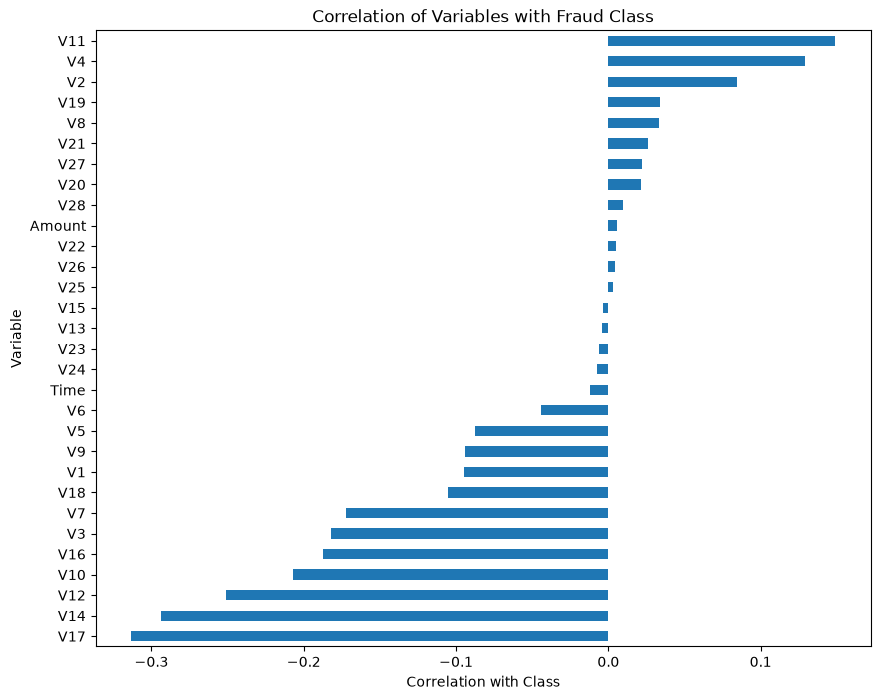

In [16]:
plt.figure(figsize=(10, 8))

correlations.plot(kind="barh")

plt.title("Correlation of Variables with Fraud Class")
plt.xlabel("Correlation with Class")
plt.ylabel("Variable")

plt.show()

## 3. Feature Preparation and Train–Test Split


The predictor variables were separated from the target variable, Class. A stratified 80/20 train–test split was used to preserve the proportion of fraudulent and legitimate transactions.

**Related report sections:** 3.6 and 3.7.


### 3.1 Separate Features and Target Variable

In [17]:
# Separate x variables and target variable

X = df.drop(columns=["Class"])
y = df["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (283726, 30)
y shape: (283726,)

Target distribution:
Class
0    283253
1       473
Name: count, dtype: int64


### 3.2 Stratified Train-Test Split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (226980, 30)
X_test: (56746, 30)
y_train: (226980,)
y_test: (56746,)


In [19]:
print("Training set:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTest set:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

Training set:
Class
0    226602
1       378
Name: count, dtype: int64
Class
0    99.833466
1     0.166534
Name: proportion, dtype: float64

Test set:
Class
0    56651
1       95
Name: count, dtype: int64
Class
0    99.832587
1     0.167413
Name: proportion, dtype: float64


## 4. Feature Scaling

In [20]:
# Create copies
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Create the scaler
scaler = StandardScaler()

# Fitting only on the training data
X_train_scaled[["Time", "Amount"]] = scaler.fit_transform(X_train[["Time", "Amount"]])

# Transformation to test data
X_test_scaled[["Time", "Amount"]] = scaler.transform(X_test[["Time", "Amount"]])

print("Feature scaling completed.")

Feature scaling completed.


In [21]:
X_train_scaled[["Time", "Amount"]].describe()

,Time,Amount
count,2.269800e+05,2.269800e+05
mean,-1.522636e-16,7.487965e-17
std,1.000002e+00,1.000002e+00
min,-1.998400e+00,-3.596386e-01
25%,-8.561822e-01,-3.364866e-01
50%,-2.123526e-01,-2.697972e-01
75%,9.363191e-01,-4.287453e-02
max,1.640237e+00,7.962087e+01


In [22]:
#Comparing Before and After Scaling
print("Before scaling:")
print(X_train[["Time", "Amount"]].head())

print("\nAfter scaling:")
print(X_train_scaled[["Time", "Amount"]].head())

Before scaling:
            Time  Amount
225399  144549.0   32.00
133746   80716.0    6.99
185792  127116.0   14.95
148925   91342.0   17.30
18398    29522.0   24.00

After scaling:
            Time    Amount
225399  1.045499 -0.229434
133746 -0.298690 -0.331197
185792  0.678397 -0.298809
148925 -0.074929 -0.289247
18398  -1.376728 -0.261985


## 5. Handling Class Imbalance Using SMOTE


SMOTE was applied to the training data to address the substantial imbalance between fraudulent and legitimate transactions. The test set retained its original class distribution to support realistic model evaluation.

**Related report sections:** 3.8 and 4.2.


In [23]:
# Check class distribution before SMOTE
print("Before SMOTE:")
print(y_train.value_counts())

# Apply SMOTE to the scaled training data only
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled,y_train)

# Check class distribution after SMOTE
print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nTraining data before SMOTE:", X_train_scaled.shape)
print("Training data after SMOTE:", X_train_smote.shape)

Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64

Training data before SMOTE: (226980, 30)
Training data after SMOTE: (453204, 30)


In [24]:
#Checking that the test set didn't change
print("Test set distribution:")
print(y_test.value_counts())

Test set distribution:
Class
0    56651
1       95
Name: count, dtype: int64


## 6. Baseline Logistic Regression Model

### 6.1 - Create and Train Model

In [25]:
# Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000,random_state=42)

# Train the model using the SMOTE data
lr_model.fit(X_train_smote, y_train_smote)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### 6.2 Generate Predictions

In [26]:
y_pred_lr = lr_model.predict(X_test_scaled)

# Predict probabilities for ROC-AUC
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

### 6.3 - Evaluation of Model

In [27]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Results")
print("--------------------------------")
print("Accuracy:", accuracy_lr)
print("Precision:", precision_lr)
print("Recall:", recall_lr)
print("F1-Score:", f1_lr)
print("ROC-AUC:", roc_auc_lr)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Results
--------------------------------
Accuracy: 0.9736721531033025
Precision: 0.053035143769968054
Recall: 0.8736842105263158
F1-Score: 0.1
ROC-AUC: 0.9618957810936585

Confusion Matrix:
[[55169  1482]
 [   12    83]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746



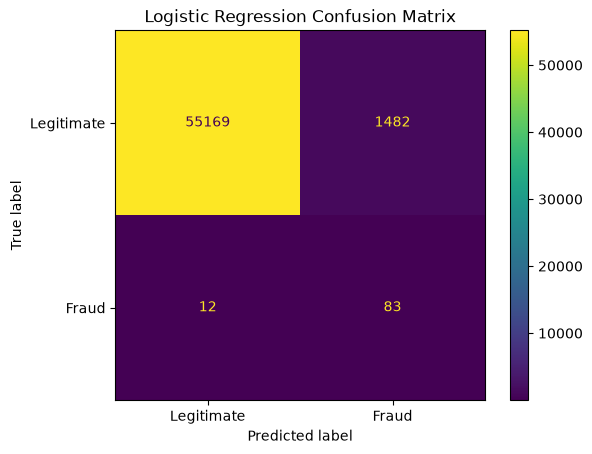

In [28]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_lr,display_labels=["Legitimate", "Fraud"])

plt.title("Logistic Regression Confusion Matrix")
plt.show()

## 7. Baseline Random Forest Model

### 7.1 - Create and Train Model

In [29]:
# Create the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)

# Train the model
rf_model.fit(X_train_smote, y_train_smote)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


### 7.2 Generate Predictions

In [30]:
y_pred_rf = rf_model.predict(X_test_scaled)

# Probability estimates for ROC-AUC
y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

### 7.3 - Evaluation of Model

In [31]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("--------------------------------")
print("Accuracy:", accuracy_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1-Score:", f1_rf)
print("ROC-AUC:", roc_auc_rf)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Results
--------------------------------
Accuracy: 0.9994713283755683
Precision: 0.9113924050632911
Recall: 0.7578947368421053
F1-Score: 0.8275862068965517
ROC-AUC: 0.9662031329404691

Confusion Matrix:
[[56644     7]
 [   23    72]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.91      0.76      0.83        95

    accuracy                           1.00     56746
   macro avg       0.96      0.88      0.91     56746
weighted avg       1.00      1.00      1.00     56746



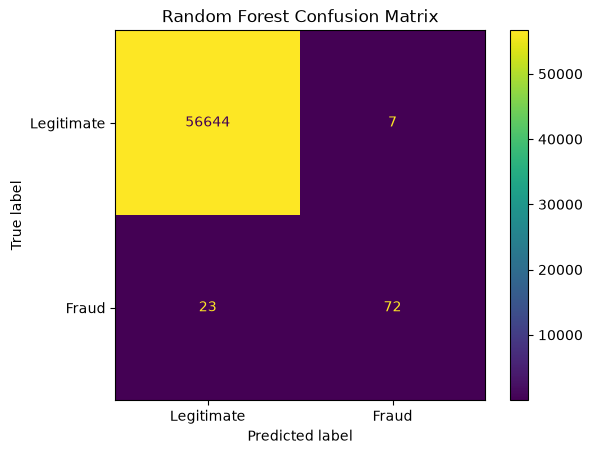

In [32]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_rf,display_labels=["Legitimate", "Fraud"])

plt.title("Random Forest Confusion Matrix")
plt.show()

### 7.4 - Random Forest Feature Importance

,Feature,Importance
14,V14,0.1945
10,V10,0.1134
12,V12,0.1002
4,V4,0.0919
17,V17,0.0915
11,V11,0.0585
3,V3,0.0563
16,V16,0.0562
2,V2,0.0391
9,V9,0.0263


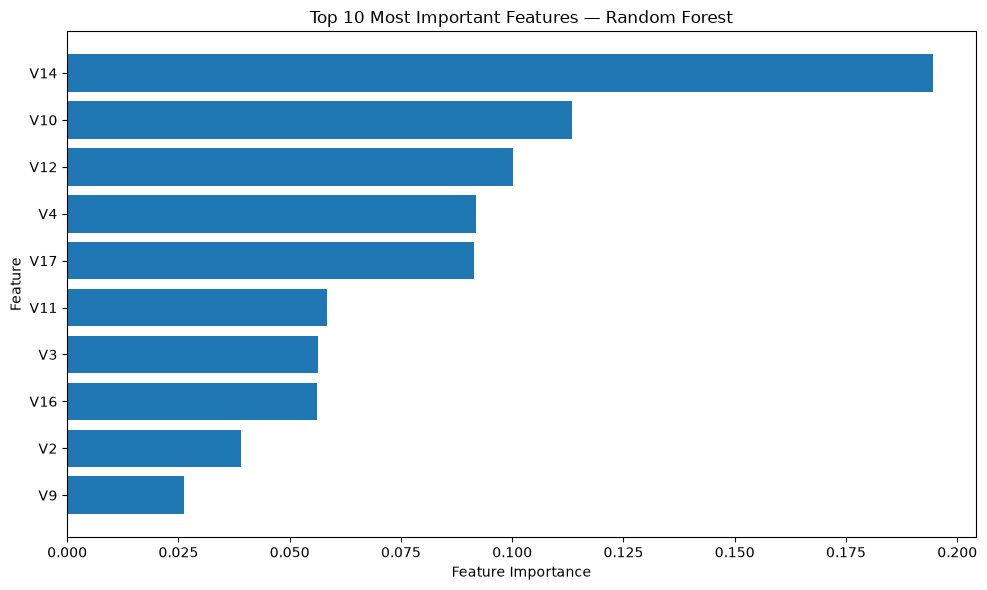

In [ ]:
# Extract feature importance from baseline Random Forest
importance = rf_model.feature_importances_

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(10).round(4))

# Plot top 10 features
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"].head(10)[::-1],
    feature_importance["Importance"].head(10)[::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Most Important Features — Random Forest")
plt.tight_layout()
plt.show()


## 8. Baseline Support Vector Machine Model

### 8.1 - Create and Train Model

In [33]:
svm_model = SVC(kernel="rbf",C=1.0,gamma="scale",random_state=42)

# Train the model
svm_model.fit(X_train_smote, y_train_smote)

print("SVM model trained successfully.")

SVM model trained successfully.


### 8.2 - Generate Predictions

In [34]:
y_pred_svm = svm_model.predict(X_test_scaled)

# Decision scores for ROC-AUC
y_score_svm = svm_model.decision_function(X_test_scaled)

### 8.3 - Evaluation of Model

In [35]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
roc_auc_svm = roc_auc_score(y_test, y_score_svm)

print("SVM Results")
print("--------------------------------")
print("Accuracy:", accuracy_svm)
print("Precision:", precision_svm)
print("Recall:", recall_svm)
print("F1-Score:", f1_svm)
print("ROC-AUC:", roc_auc_svm)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Results
--------------------------------
Accuracy: 0.9856729989779015
Precision: 0.09111617312072894
Recall: 0.8421052631578947
F1-Score: 0.1644398766700925
ROC-AUC: 0.9572232199180764

Confusion Matrix:
[[55853   798]
 [   15    80]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56651
           1       0.09      0.84      0.16        95

    accuracy                           0.99     56746
   macro avg       0.55      0.91      0.58     56746
weighted avg       1.00      0.99      0.99     56746



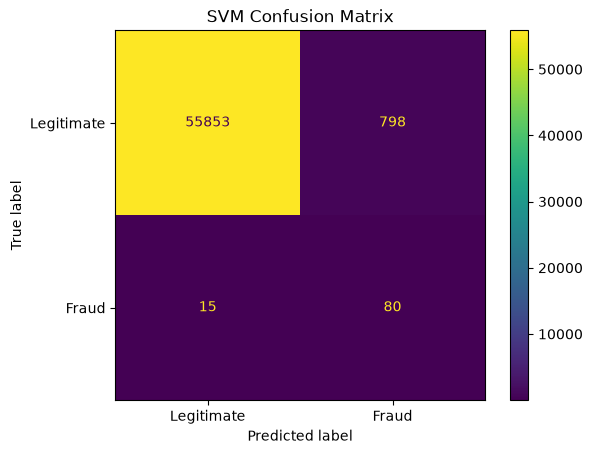

In [36]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_svm,display_labels=["Legitimate", "Fraud"])

plt.title("SVM Confusion Matrix")
plt.show()

## 9. SMOTE Effectiveness: With and Without Oversampling


This section compares Logistic Regression, Random Forest and Support Vector Machine models with and without SMOTE. A separate stratified validation experiment was used to evaluate how oversampling affected precision, recall, F1-score and average precision.

**Related report sections:** 4.4 and 5.3.


### 9.1 - Validation Data Preparation

In [ ]:
# Create a validation set from the original training data
X_smote_train, X_smote_val, y_smote_train, y_smote_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training distribution:")
print(y_smote_train.value_counts())

print("\nValidation distribution:")
print(y_smote_val.value_counts())


Training distribution:
Class
0    181282
1       302
Name: count, dtype: int64

Validation distribution:
Class
0    45320
1       76
Name: count, dtype: int64


### 9.2 — Logistic Regression: With versus without SMOTE

In [ ]:
# Condition 1: Without SMOTE
lr_no_smote = SkPipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Condition 2: With SMOTE
lr_with_smote = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Fit both models using the same training data
lr_no_smote.fit(X_smote_train, y_smote_train)
lr_with_smote.fit(X_smote_train, y_smote_train)

# Evaluate only on the validation partition
results_lr = []

for name, model in [
    ("Without SMOTE", lr_no_smote),
    ("With SMOTE", lr_with_smote)
]:
    predictions = model.predict(X_smote_val)
    scores = model.predict_proba(X_smote_val)[:, 1]
    tn, fp, fn, tp = confusion_matrix(
        y_smote_val, predictions, labels=[0, 1]
    ).ravel()

    results_lr.append({
        "Condition": name,
        "Precision": precision_score(
            y_smote_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_smote_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_smote_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_smote_val, scores),
        "Average Precision": average_precision_score(
            y_smote_val, scores
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

lr_comparison = pd.DataFrame(results_lr)
display(lr_comparison.round(4))


,Condition,Precision,Recall,F1-Score,ROC-AUC,Average Precision,False Positives,False Negatives
0,Without SMOTE,0.9123,0.6842,0.7820,0.9685,0.8226,5,24
1,With SMOTE,0.0508,0.9079,0.0962,0.9732,0.8138,1289,7


### 9.3 — Random Forest: With vs Without SMOTE

In [ ]:
# Condition 1: Random Forest without SMOTE
rf_no_smote = SkPipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Condition 2: Random Forest with SMOTE
rf_with_smote = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train both models
rf_no_smote.fit(X_smote_train, y_smote_train)
rf_with_smote.fit(X_smote_train, y_smote_train)

# Evaluate on the same validation dataset
results_rf = []

for name, model in [
    ("Without SMOTE", rf_no_smote),
    ("With SMOTE", rf_with_smote)
]:
    predictions = model.predict(X_smote_val)
    scores = model.predict_proba(X_smote_val)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_smote_val, predictions, labels=[0, 1]
    ).ravel()

    results_rf.append({
        "Condition": name,
        "Precision": precision_score(
            y_smote_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_smote_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_smote_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_smote_val, scores),
        "Average Precision": average_precision_score(
            y_smote_val, scores
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

rf_comparison = pd.DataFrame(results_rf)
display(rf_comparison.round(4))


,Condition,Precision,Recall,F1-Score,ROC-AUC,Average Precision,False Positives,False Negatives
0,Without SMOTE,0.9552,0.8421,0.8951,0.9395,0.8672,3,12
1,With SMOTE,0.9286,0.8553,0.8904,0.9740,0.8792,5,11


### 9.4 — SVM with and without SMOTE

In [ ]:
# Create a reproducible stratified subset for SVM
X_svm_train, _, y_svm_train, _ = train_test_split(
    X_smote_train,
    y_smote_train,
    train_size=50000,
    random_state=42,
    stratify=y_smote_train
)

print("SVM training subset distribution:")
print(y_svm_train.value_counts())

# SVM without SMOTE
svm_no_smote = SkPipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

# SVM with SMOTE
svm_with_smote = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

# Train both configurations
svm_no_smote.fit(X_svm_train, y_svm_train)
svm_with_smote.fit(X_svm_train, y_svm_train)

# Evaluate on the same untouched validation set
results_svm = []

for name, model in [
    ("Without SMOTE", svm_no_smote),
    ("With SMOTE", svm_with_smote)
]:
    predictions = model.predict(X_smote_val)
    scores = model.decision_function(X_smote_val)

    tn, fp, fn, tp = confusion_matrix(
        y_smote_val, predictions, labels=[0, 1]
    ).ravel()

    results_svm.append({
        "Condition": name,
        "Precision": precision_score(
            y_smote_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_smote_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_smote_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_smote_val, scores),
        "Average Precision": average_precision_score(
            y_smote_val, scores
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

svm_comparison = pd.DataFrame(results_svm)
display(svm_comparison.round(4))


SVM training subset distribution:
Class
0    49917
1       83
Name: count, dtype: int64


,Condition,Precision,Recall,F1-Score,ROC-AUC,Average Precision,False Positives,False Negatives
0,Without SMOTE,1.0000,0.3684,0.5385,0.9243,0.8413,0,48
1,With SMOTE,0.1484,0.7500,0.2478,0.9242,0.3258,327,19


### 9.5 Consolidated SMOTE Effectiveness Results

In [55]:

# Combine the results from all three experiments
lr_results = lr_comparison.copy()
rf_results = rf_comparison.copy()
svm_results = svm_comparison.copy()

lr_results.insert(0, "Model", "Logistic Regression")
rf_results.insert(0, "Model", "Random Forest")
svm_results.insert(0, "Model", "SVM")

smote_results = pd.concat(
    [lr_results, rf_results, svm_results],
    ignore_index=True
)

display(smote_results.round(4))


,Model,Condition,Precision,Recall,F1-Score,ROC-AUC,Average Precision,False Positives,False Negatives
0,Logistic Regression,Without SMOTE,0.9123,0.6842,0.7820,0.9685,0.8226,5,24
1,Logistic Regression,With SMOTE,0.0508,0.9079,0.0962,0.9732,0.8138,1289,7
2,Random Forest,Without SMOTE,0.9552,0.8421,0.8951,0.9395,0.8672,3,12
3,Random Forest,With SMOTE,0.9286,0.8553,0.8904,0.9740,0.8792,5,11
4,SVM,Without SMOTE,1.0000,0.3684,0.5385,0.9243,0.8413,0,48
5,SVM,With SMOTE,0.1484,0.7500,0.2478,0.9242,0.3258,327,19


### 9.6 Precision-Recall Curve Analysis

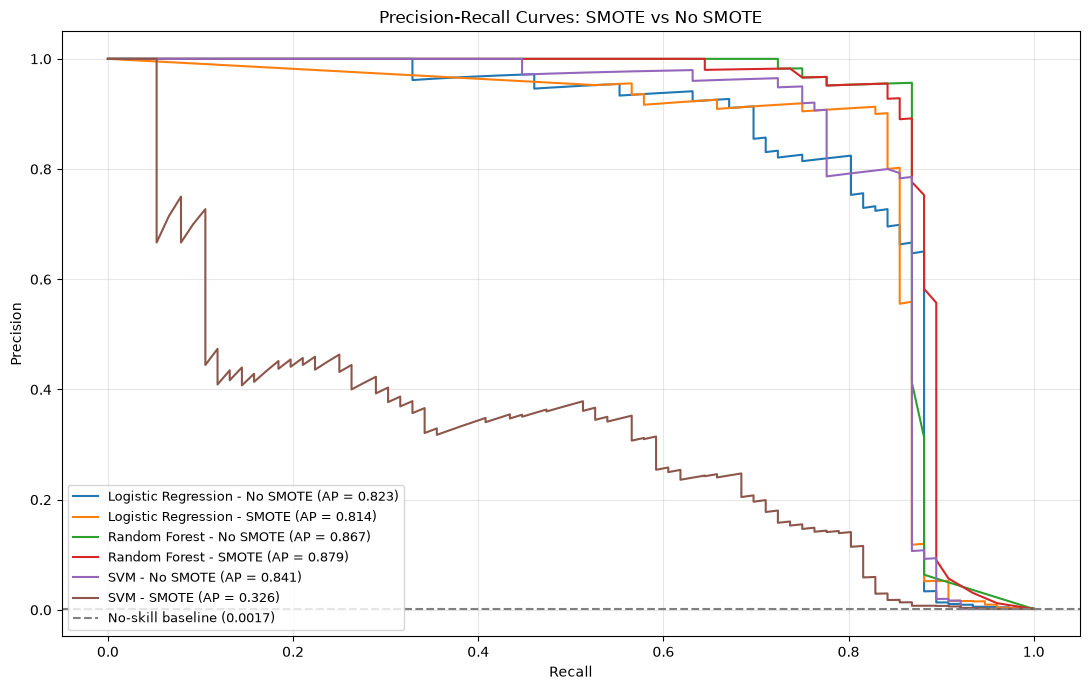

In [ ]:
models = {
    "Logistic Regression - No SMOTE": lr_no_smote,
    "Logistic Regression - SMOTE": lr_with_smote,
    "Random Forest - No SMOTE": rf_no_smote,
    "Random Forest - SMOTE": rf_with_smote,
    "SVM - No SMOTE": svm_no_smote,
    "SVM - SMOTE": svm_with_smote
}

plt.figure(figsize=(11, 7))

for name, model in models.items():

    if "SVM" in name:
        scores = model.decision_function(X_smote_val)
    else:
        scores = model.predict_proba(X_smote_val)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_smote_val, scores
    )

    ap = average_precision_score(y_smote_val, scores)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.3f})"
    )

# Random-classifier reference
fraud_rate = y_smote_val.mean()
plt.axhline(
    y=fraud_rate,
    color="gray",
    linestyle="--",
    label=f"No-skill baseline ({fraud_rate:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves: SMOTE vs No SMOTE")
plt.legend(loc="best", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Hyperparameter Optimisation Using GridSearchCV


GridSearchCV was used to optimise model hyperparameters using F1-score as the selection metric. Stratified cross-validation was applied, with SMOTE incorporated into the training pipelines to reduce data leakage.

**Related report sections:** 3.9, 4.5 and 5.4.


### 10.1 - Logistic Regression

In [57]:
# Scale only Time and Amount
preprocessor = ColumnTransformer(transformers=[("scale", StandardScaler(), ["Time", "Amount"])],remainder="passthrough")

# Build pipeline
lr_pipeline = Pipeline([("preprocessor", preprocessor),("smote", SMOTE(random_state=42)),("model", LogisticRegression(max_iter=1000,random_state=42))])

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


In [58]:
cv = StratifiedKFold(n_splits=10,shuffle=True,random_state=42)

In [59]:
lr_param_grid = {"model__C": [0.01, 0.1, 1, 10, 100]}

In [60]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

lr_grid = GridSearchCV(estimator=lr_pipeline,param_grid=lr_param_grid,scoring=scoring,refit="f1",cv=cv,n_jobs=1,verbose=1,return_train_score=True)

In [61]:
lr_grid.fit(X_train, y_train)

Fitting 10 folds for each of 5 candidates, totalling 50 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall', ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... sh

In [62]:
print("Best Logistic Regression Parameters:")
print(lr_grid.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(lr_grid.best_score_)

Best Logistic Regression Parameters:
{'model__C': 0.01}

Best Cross-Validation F1-Score:
0.10824083952544891


In [63]:
best_lr = lr_grid.best_estimator_

# Predictions
y_pred_lr_tuned = best_lr.predict(X_test)

# Probabilities for ROC-AUC
y_prob_lr_tuned = best_lr.predict_proba(X_test)[:, 1]

In [64]:
accuracy_lr_tuned = accuracy_score(y_test, y_pred_lr_tuned)
precision_lr_tuned = precision_score(y_test, y_pred_lr_tuned)
recall_lr_tuned = recall_score(y_test, y_pred_lr_tuned)
f1_lr_tuned = f1_score(y_test, y_pred_lr_tuned)
roc_auc_lr_tuned = roc_auc_score(y_test, y_prob_lr_tuned)

print("Tuned Logistic Regression Results")
print("----------------------------------")
print("Accuracy:", accuracy_lr_tuned)
print("Precision:", precision_lr_tuned)
print("Recall:", recall_lr_tuned)
print("F1-Score:", f1_lr_tuned)
print("ROC-AUC:", roc_auc_lr_tuned)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_tuned))

Tuned Logistic Regression Results
----------------------------------
Accuracy: 0.9741479575652909
Precision: 0.053966189856957086
Recall: 0.8736842105263158
F1-Score: 0.10165339865278629
ROC-AUC: 0.9616897179313042

Confusion Matrix:
[[55196  1455]
 [   12    83]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746



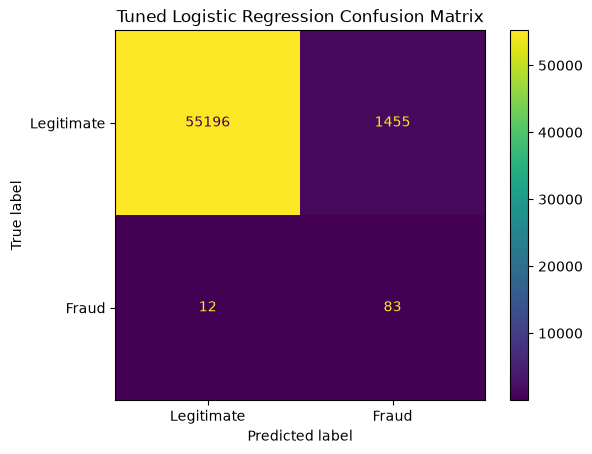

In [65]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr_tuned,
    display_labels=["Legitimate", "Fraud"]
)

plt.title("Tuned Logistic Regression Confusion Matrix")
plt.show()

### 10.2 - Random Forest

In [66]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

In [67]:
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20],
    "model__min_samples_split": [2],
    "model__min_samples_leaf": [1, 2]
}

In [ ]:
rf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [ ]:
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring=scoring,
    refit="f1",
    cv=rf_cv,
    n_jobs=1,
    verbose=2,
    return_train_score=False
)


In [ ]:
X_rf_sample, _, y_rf_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=50000,
    random_state=42,
    stratify=y_train
)

rf_grid.fit(X_rf_sample, y_rf_sample)

print("Best Parameters:", rf_grid.best_params_)
print("Best CV F1-Score:", rf_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END model__max_depth=10, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=100; total time=  16.3s
[CV] END model__max_depth=10, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=100; total time=  14.3s
[CV] END model__max_depth=10, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=100; total time=  15.1s
[CV] END model__max_depth=10, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=100; total time=  14.8s
[CV] END model__max_depth=10, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=100; total time=  18.8s
[CV] END model__max_depth=10, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=200; total time=  36.9s
[CV] END model__max_depth=10, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=200; total time=  28.6s
[CV] END model__max_depth=10, model__

In [79]:
print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(rf_grid.best_score_)

Best Random Forest Parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Best Cross-Validation F1-Score:
0.8112682348925233


In [ ]:
best_rf = clone(rf_grid.best_estimator_)
best_rf.fit(X_train, y_train)

y_pred_rf_tuned = best_rf.predict(X_test)
y_prob_rf_tuned = best_rf.predict_proba(X_test)[:, 1]

accuracy_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)
precision_rf_tuned = precision_score(y_test, y_pred_rf_tuned)
recall_rf_tuned = recall_score(y_test, y_pred_rf_tuned)
f1_rf_tuned = f1_score(y_test, y_pred_rf_tuned)
roc_auc_rf_tuned = roc_auc_score(y_test, y_prob_rf_tuned)

print("Tuned Random Forest Results")
print("--------------------------------")
print("Accuracy:", accuracy_rf_tuned)
print("Precision:", precision_rf_tuned)
print("Recall:", recall_rf_tuned)
print("F1-Score:", f1_rf_tuned)
print("ROC-AUC:", roc_auc_rf_tuned)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_tuned))

Tuned Random Forest Results
--------------------------------
Accuracy: 0.9993832164381631
Precision: 0.8488372093023255
Recall: 0.7684210526315789
F1-Score: 0.8066298342541437
ROC-AUC: 0.9577499909417683

Confusion Matrix:
[[56638    13]
 [   22    73]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.77      0.81        95

    accuracy                           1.00     56746
   macro avg       0.92      0.88      0.90     56746
weighted avg       1.00      1.00      1.00     56746



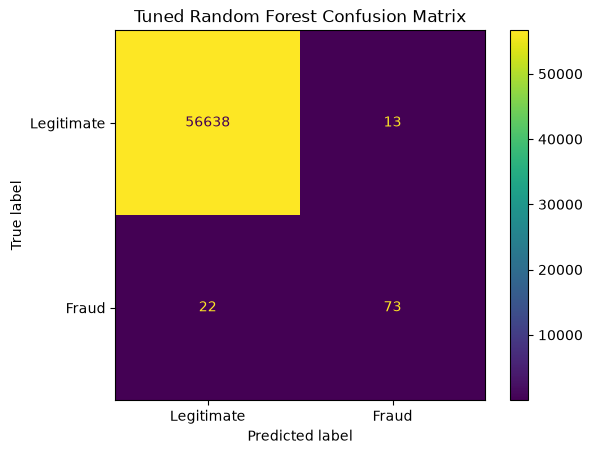

In [85]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf_tuned,
    display_labels=["Legitimate", "Fraud"]
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.show()

In [86]:
print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(rf_grid.best_score_)

print("\nROC-AUC:")
print(roc_auc_rf_tuned)

Best Random Forest Parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Best Cross-Validation F1-Score:
0.8112682348925233

ROC-AUC:
0.9577499909417683


,Fold,F1-Score
0,1,0.8387
1,2,0.7407
2,3,0.7500
3,4,0.9412
4,5,0.7857


Mean F1-Score: 0.8113
Standard Deviation: 0.0735


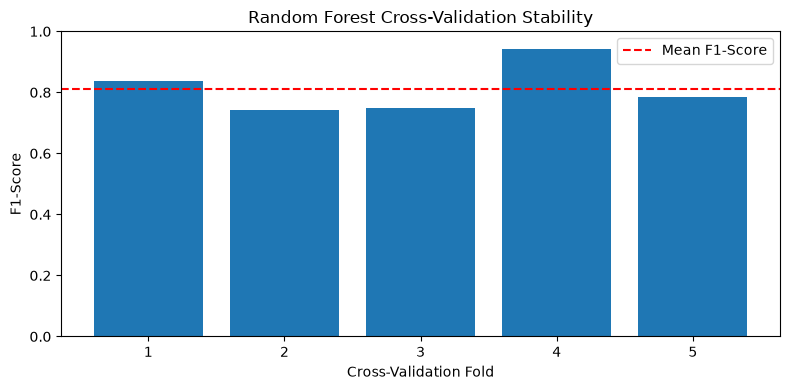

In [ ]:
# Extract F1-scores for the best Random Forest configuration
best_index = rf_grid.best_index_

fold_scores = [
    rf_grid.cv_results_[f"split{i}_test_f1"][best_index]
    for i in range(rf_grid.n_splits_)
]

cv_stability = pd.DataFrame({
    "Fold": range(1, len(fold_scores) + 1),
    "F1-Score": fold_scores
})

display(cv_stability.round(4))

print("Mean F1-Score:", round(cv_stability["F1-Score"].mean(), 4))
print("Standard Deviation:", round(cv_stability["F1-Score"].std(ddof=0), 4))

# Plot cross-validation stability
plt.figure(figsize=(8, 4))

plt.bar(cv_stability["Fold"], cv_stability["F1-Score"])

plt.axhline(
    cv_stability["F1-Score"].mean(),
    color="red",
    linestyle="--",
    label="Mean F1-Score"
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("F1-Score")
plt.title("Random Forest Cross-Validation Stability")
plt.ylim(0, 1)
plt.xticks(cv_stability["Fold"])
plt.legend()
plt.tight_layout()
plt.show()


### 10.3 - SVM

In [87]:
# Create a stratified subset for SVM hyperparameter tuning
X_svm_tune, _, y_svm_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=50000,
    stratify=y_train,
    random_state=42
)

print("SVM tuning subset shape:", X_svm_tune.shape)
print("\nClass distribution:")
print(y_svm_tune.value_counts())

SVM tuning subset shape: (50000, 30)

Class distribution:
Class
0    49917
1       83
Name: count, dtype: int64


In [88]:
svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", SVC(
        random_state=42,
        cache_size=1000
    ))
])

In [89]:
svm_param_grid = [
    {
        "model__kernel": ["linear"],
        "model__C": [1]
    },
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1],
        "model__gamma": ["scale", 0.1]
    }
]

In [90]:
svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring=scoring,
    refit="f1",
    cv=rf_cv,
    n_jobs=1,
    verbose=2,
    return_train_score=False
)

In [91]:
svm_grid.fit(X_svm_tune, y_svm_tune)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END ...................model__C=1, model__kernel=linear; total time=  25.2s
[CV] END ...................model__C=1, model__kernel=linear; total time=  20.4s
[CV] END ...................model__C=1, model__kernel=linear; total time=  25.0s
[CV] END ...................model__C=1, model__kernel=linear; total time=  27.3s
[CV] END ...................model__C=1, model__kernel=linear; total time=  15.1s
[CV] END model__C=0.1, model__gamma=scale, model__kernel=rbf; total time=  20.9s
[CV] END model__C=0.1, model__gamma=scale, model__kernel=rbf; total time=  38.5s
[CV] END model__C=0.1, model__gamma=scale, model__kernel=rbf; total time=  43.1s
[CV] END model__C=0.1, model__gamma=scale, model__kernel=rbf; total time=  21.1s
[CV] END model__C=0.1, model__gamma=scale, model__kernel=rbf; total time=  15.3s
[CV] END ..model__C=0.1, model__gamma=0.1, model__kernel=rbf; total time=  22.5s
[CV] END ..model__C=0.1, model__gamma=0.1, model_

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'model__C': [1], 'model__kernel': ['linear']}, {'model__C': [0.1, 1], 'model__gamma': ['scale', 0.1], 'model__kernel': ['rbf']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall', ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... ve

In [92]:
print("Best SVM Parameters:")
print(svm_grid.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(svm_grid.best_score_)

Best SVM Parameters:
{'model__C': 1, 'model__gamma': 0.1, 'model__kernel': 'rbf'}

Best Cross-Validation F1-Score:
0.1782111801242236


In [93]:
best_svm_params = svm_grid.best_params_

final_svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", SVC(
        C=best_svm_params["model__C"],
        kernel=best_svm_params["model__kernel"],
        gamma=best_svm_params.get("model__gamma", "scale"),
        random_state=42,
        cache_size=1000
    ))
])

In [94]:
final_svm_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](30,)","['Time','V1','V2',...,'V27','V28','Amount']"
n_features_in_,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scale', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [95]:
y_pred_svm_tuned = final_svm_pipeline.predict(X_test)
y_score_svm_tuned = final_svm_pipeline.decision_function(X_test)

accuracy_svm_tuned = accuracy_score(y_test, y_pred_svm_tuned)
precision_svm_tuned = precision_score(y_test, y_pred_svm_tuned)
recall_svm_tuned = recall_score(y_test, y_pred_svm_tuned)
f1_svm_tuned = f1_score(y_test, y_pred_svm_tuned)
roc_auc_svm_tuned = roc_auc_score(y_test, y_score_svm_tuned)

print("Tuned SVM Results")
print("--------------------------------")
print("Accuracy:", accuracy_svm_tuned)
print("Precision:", precision_svm_tuned)
print("Recall:", recall_svm_tuned)
print("F1-Score:", f1_svm_tuned)
print("ROC-AUC:", roc_auc_svm_tuned)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm_tuned))

Tuned SVM Results
--------------------------------
Accuracy: 0.9985373418390724
Precision: 0.5882352941176471
Recall: 0.42105263157894735
F1-Score: 0.49079754601226994
ROC-AUC: 0.9465190840687534

Confusion Matrix:
[[56623    28]
 [   55    40]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.59      0.42      0.49        95

    accuracy                           1.00     56746
   macro avg       0.79      0.71      0.75     56746
weighted avg       1.00      1.00      1.00     56746



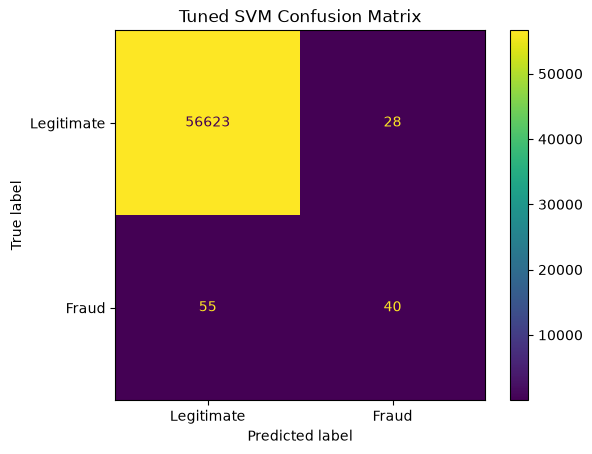

In [96]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm_tuned,
    display_labels=["Legitimate", "Fraud"]
)

plt.title("Tuned SVM Confusion Matrix")
plt.show()

In [97]:
print("Best SVM Parameters:")
print(svm_grid.best_params_)

print("\nBest SVM Cross-Validation F1-Score:")
print(svm_grid.best_score_)

Best SVM Parameters:
{'model__C': 1, 'model__gamma': 0.1, 'model__kernel': 'rbf'}

Best SVM Cross-Validation F1-Score:
0.1782111801242236


## 11. Model Comparison and Error Analysis


This section compares the classification performance of the models and examines feature importance, cross-validation stability and misclassification patterns. The findings support the model selection and discussion presented in the research report.

**Related report sections:** 4.6–4.9 and 5.2–5.7.


In [ ]:
comparison_table = pd.DataFrame({
    "Model": [
        "Logistic Regression - Baseline",
        "Logistic Regression - Tuned",
        "Random Forest - Baseline",
        "Random Forest - Tuned",
        "SVM - Baseline",
        "SVM - Tuned"
    ],

    "Accuracy": [
        accuracy_lr,
        accuracy_lr_tuned,
        accuracy_rf,
        accuracy_rf_tuned,
        accuracy_svm,
        accuracy_svm_tuned
    ],

    "Precision": [
        precision_lr,
        precision_lr_tuned,
        precision_rf,
        precision_rf_tuned,
        precision_svm,
        precision_svm_tuned
    ],

    "Recall": [
        recall_lr,
        recall_lr_tuned,
        recall_rf,
        recall_rf_tuned,
        recall_svm,
        recall_svm_tuned
    ],

    "F1-Score": [
        f1_lr,
        f1_lr_tuned,
        f1_rf,
        f1_rf_tuned,
        f1_svm,
        f1_svm_tuned
    ],

    "ROC-AUC": [
        roc_auc_lr,
        roc_auc_lr_tuned,
        roc_auc_rf,
        roc_auc_rf_tuned,
        roc_auc_svm,
        roc_auc_svm_tuned
    ]
})

comparison_table

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression - Baseline,0.973672,0.053035,0.873684,0.100000,0.961896
1,Logistic Regression - Tuned,0.974148,0.053966,0.873684,0.101653,0.961690
2,Random Forest - Baseline,0.999471,0.911392,0.757895,0.827586,0.966203
3,Random Forest - Tuned,0.999383,0.848837,0.768421,0.806630,0.957750
4,SVM - Baseline,0.985673,0.091116,0.842105,0.164440,0.957223
5,SVM - Tuned,0.998537,0.588235,0.421053,0.490798,0.946519


In [99]:
comparison_table_rounded = comparison_table.copy()

comparison_table_rounded[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
] = comparison_table_rounded[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
].round(4)

comparison_table_rounded

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression - Baseline,0.9737,0.0530,0.8737,0.1000,0.9619
1,Logistic Regression - Tuned,0.9741,0.0540,0.8737,0.1017,0.9617
2,Random Forest - Baseline,0.9995,0.9114,0.7579,0.8276,0.9662
3,Random Forest - Tuned,0.9994,0.8488,0.7684,0.8066,0.9577
4,SVM - Baseline,0.9857,0.0911,0.8421,0.1644,0.9572
5,SVM - Tuned,0.9985,0.5882,0.4211,0.4908,0.9465


In [100]:
tuned_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Support Vector Machine"
    ],

    "Accuracy": [
        accuracy_lr_tuned,
        accuracy_rf_tuned,
        accuracy_svm_tuned
    ],

    "Precision": [
        precision_lr_tuned,
        precision_rf_tuned,
        precision_svm_tuned
    ],

    "Recall": [
        recall_lr_tuned,
        recall_rf_tuned,
        recall_svm_tuned
    ],

    "F1-Score": [
        f1_lr_tuned,
        f1_rf_tuned,
        f1_svm_tuned
    ],

    "ROC-AUC": [
        roc_auc_lr_tuned,
        roc_auc_rf_tuned,
        roc_auc_svm_tuned
    ]
})

tuned_comparison = tuned_comparison.round(4)

tuned_comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9741,0.0540,0.8737,0.1017,0.9617
1,Random Forest,0.9994,0.8488,0.7684,0.8066,0.9577
2,Support Vector Machine,0.9985,0.5882,0.4211,0.4908,0.9465


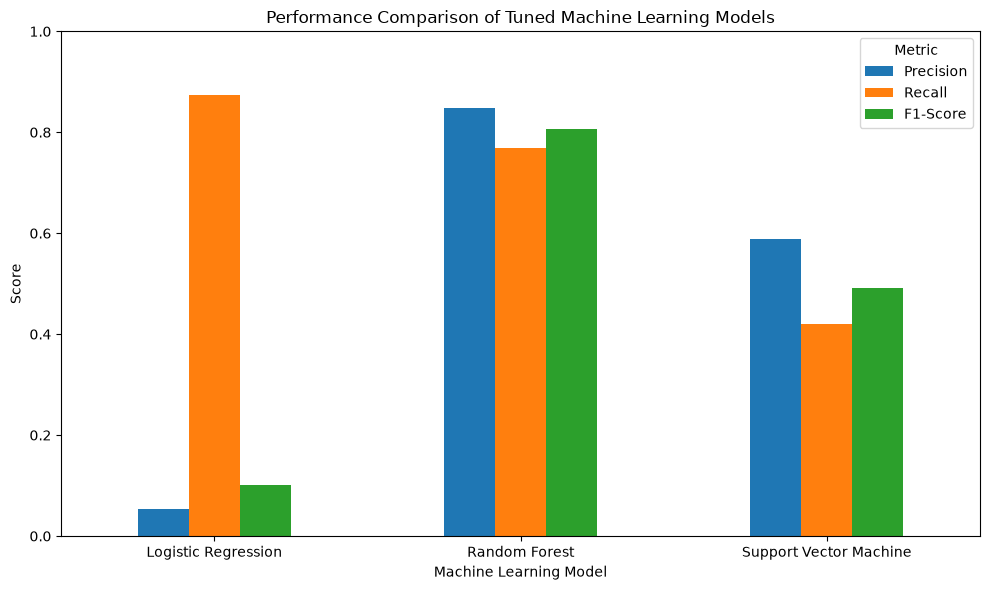

In [104]:
# Compare Precision, Recall and F1-Score for tuned models

metrics_to_plot = tuned_comparison.set_index("Model")[
    ["Precision", "Recall", "F1-Score"]
]

ax = metrics_to_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of Tuned Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()

plt.show()

### 11.1 - Random Forest Error Analysis

In [ ]:
# Analyse baseline Random Forest predictions
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_rf, labels=[0, 1]
).ravel()

error_summary = pd.DataFrame({
    "Classification": [
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    "Count": [tn, fp, fn, tp]
})

display(error_summary)


,Classification,Count
0,True Negative,56644
1,False Positive,7
2,False Negative,23
3,True Positive,72


### 11.2 — Analysis of Misclassified Transactions

In [109]:

# Compare transaction amounts by prediction outcome
error_data = X_test.copy()

error_data["Actual"] = y_test
error_data["Predicted"] = y_pred_rf

error_data["Outcome"] = "True Negative"
error_data.loc[
    (error_data["Actual"] == 0) &
    (error_data["Predicted"] == 1),
    "Outcome"
] = "False Positive"

error_data.loc[
    (error_data["Actual"] == 1) &
    (error_data["Predicted"] == 0),
    "Outcome"
] = "False Negative"

error_data.loc[
    (error_data["Actual"] == 1) &
    (error_data["Predicted"] == 1),
    "Outcome"
] = "True Positive"

amount_summary = error_data.groupby("Outcome")["Amount"].agg(
    ["count", "mean", "median", "min", "max"]
)

display(amount_summary.round(2))


,count,mean,median,min,max
Outcome,,,,,
False Negative,23,254.67,3.79,0.0,1809.68
False Positive,7,181.35,83.40,1.0,911.09
True Negative,56644,88.69,21.60,0.0,25691.16
True Positive,72,123.73,24.20,0.0,1354.25


### 11.3 - Transaction Amount Distribution

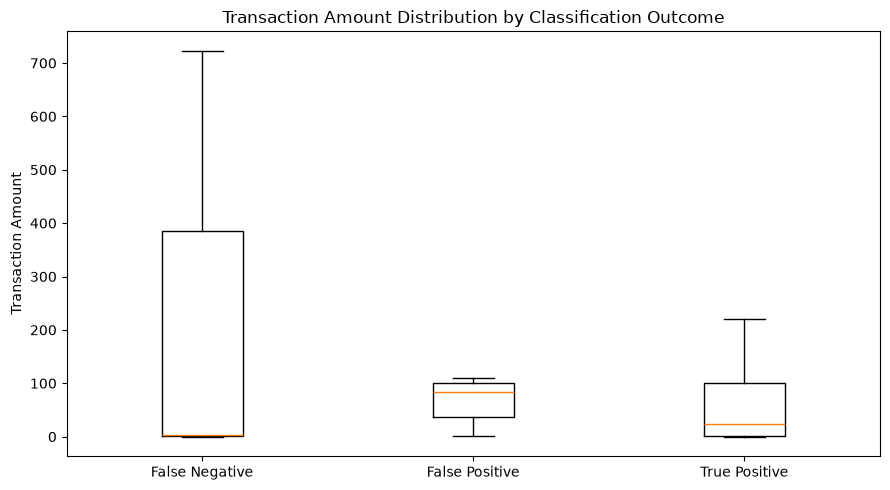

In [ ]:
categories = ["False Negative", "False Positive", "True Positive"]

plot_data = [
    error_data.loc[error_data["Outcome"] == category, "Amount"]
    for category in categories
]

plt.figure(figsize=(9, 5))
plt.boxplot(plot_data, tick_labels=categories, showfliers=False)

plt.ylabel("Transaction Amount")
plt.title("Transaction Amount Distribution by Classification Outcome")
plt.tight_layout()
plt.show()